# UK Biobank LaMoD Verification - Reference-Based Tracking (Lagomorph-Free)

This notebook demonstrates **reference-based cardiac motion tracking** with verification on UK Biobank data using the **lagomorph-free implementation**.

**Pipeline:**
1. Load UK Biobank cardiac cine MRI data
2. Whole heart detection and preprocessing  
3. CarSON myocardium segmentation
4. **Reference-based LaMoD tracking**: frame 0 → all other frames
5. **Verification**: Deform reference mask and compute Dice scores
6. **Visualization**: 8-panel comparison + strain analysis

**Key Features:** 
- Proper reference-based tracking (frame 0 as end-diastole reference)
- **Uses lagomorph-free implementation** (pure PyTorch, no CUDA extensions)

**Dataset:** UK Biobank sample - Subject 1002514

## 1. Setup

In [1]:
%load_ext autoreload
%autoreload 2
%cd /gpfs/gibbs/project/kwan/jx332/code/2025-08-LaMoD

import numpy as np
import torch
import matplotlib.pyplot as plt
from pathlib import Path
from skimage.transform import resize
import sys

# Set random seeds
np.random.seed(42)
torch.manual_seed(42)

/gpfs/gibbs/project/kwan/jx332/code/2025-08-LaMoD


In [2]:
# Setup device
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '0'
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

PyTorch version: 2.6.0+cu124
CUDA available: True
GPU: NVIDIA GeForce RTX 3090


## 2. Load Configuration (Following inference-registration.ipynb)

In [3]:
import json

config_fname = 'configs/ours-pretrain-registration-aligned-frames.json'
config = json.load(open(config_fname))

print(f"Loaded config from: {config_fname}")
print(f"Networks: {list(config['networks'].keys())}")

Loaded config from: configs/ours-pretrain-registration-aligned-frames.json
Networks: ['registration']


## 3. Load UK Biobank Data

In [4]:
# Load UK Biobank NPY file
ukb_data_path = Path('/vast/palmer/pi/kwan/jx332/data/2025-10-12-UKB-sample/unified_analysis_results/segmented/1002514.npy')
print(f"Loading data from: {ukb_data_path}")

ukb_data = np.load(ukb_data_path, allow_pickle=True).item()
print(f"Subject ID: {ukb_data.get('subject_id', 'N/A')}")
print(f"Number of series: {len(ukb_data.get('series_list', []))}")

Loading data from: /vast/palmer/pi/kwan/jx332/data/2025-10-12-UKB-sample/unified_analysis_results/segmented/1002514.npy
Subject ID: 1002514
Number of series: 18


In [5]:
# Select middle short axis slice
sas_series = []
for i, series in enumerate(ukb_data['series_list']):
    series_info = series.get('info', {})
    view = series_info.get('view', '').lower()
    if 'sas' in view:
        sas_series.append((i, series))

middle_sas_idx = len(sas_series) // 2
selected_series_idx, selected_series = sas_series[middle_sas_idx]

print(f"Found {len(sas_series)} SAS series")
print(f"Selected series {selected_series_idx} (position {middle_sas_idx+1} of {len(sas_series)})")

# Extract temporal frames
temporal_frames = selected_series['slices']
n_frames = len(temporal_frames)
images = np.array([frame['image'] for frame in temporal_frames])

# Normalize to [0, 1]
images = images.astype(np.float32)
images = (images - images.min()) / (images.max() - images.min() + 1e-8)

print(f"\nImages shape: {images.shape}")
print(f"  {images.shape[0]} temporal frames of {images.shape[1]}x{images.shape[2]} pixels")

Found 13 SAS series
Selected series 11 (position 7 of 13)

Images shape: (50, 208, 192)
  50 temporal frames of 208x192 pixels


## 4. Rescale to 1mm² Spatial Resolution

**Important**: The LaMoD network was trained on data with 1mm² spatial resolution. UKB data has different resolution (e.g., 1.83mm²), so we need to rescale before preprocessing.

In [6]:
# Get spatial resolution from UKB data
ukb_pixel_spacing = selected_series['slices'][0].get('pixel_spacing', [1.83, 1.83])
print(f"Original UKB pixel spacing: {ukb_pixel_spacing} mm")

# Target resolution: 1mm x 1mm (what LaMoD was trained on)
target_spacing = [1.0, 1.0]

# Calculate scaling factor
scale_factor_y = ukb_pixel_spacing[0] / target_spacing[0]
scale_factor_x = ukb_pixel_spacing[1] / target_spacing[1]

print(f"Scaling factors: {scale_factor_y:.3f} (Y), {scale_factor_x:.3f} (X)")

# Rescale all frames to 1mm² resolution
from skimage.transform import resize

rescaled_frames = []
original_shape = images.shape[1:3]
new_shape = (int(original_shape[0] * scale_factor_y), 
             int(original_shape[1] * scale_factor_x))

print(f"Rescaling from {original_shape} to {new_shape} pixels")

for frame in images:
    rescaled = resize(frame, new_shape, anti_aliasing=True, preserve_range=True)
    rescaled_frames.append(rescaled)

images_1mm = np.array(rescaled_frames, dtype=np.float32)

print(f"\nRescaled images shape: {images_1mm.shape}")
print(f"Spatial resolution now: 1mm x 1mm")
print(f"Value range: [{images_1mm.min():.3f}, {images_1mm.max():.3f}]")

Original UKB pixel spacing: [1.83, 1.83] mm
Scaling factors: 1.830 (Y), 1.830 (X)
Rescaling from (208, 192) to (380, 351) pixels

Rescaled images shape: (50, 380, 351)
Spatial resolution now: 1mm x 1mm
Value range: [0.000, 0.972]


## 4. Preprocessing: Whole Heart Detection + Cropping

In [7]:
# Add toolkit path
sys.path.append('/gpfs/gibbs/project/kwan/jx332/code/2025-04-Cardiac-Img-Preprocessing-Toolkit')

from cardiac_toolkit.detection import WholeHeartDetectorYOLOv9
from cardiac_toolkit.detection.utils.bbox_utils import rescale_bbox

detector_model_path = '/gpfs/gibbs/project/kwan/jx332/code/2025-04-Cardiac-Img-Preprocessing-Toolkit/cardiac_toolkit/detection/models/whole_heart_yolov9/checkpoints/best.onnx'
detector = WholeHeartDetectorYOLOv9(model_path=detector_model_path)

# Detect on first frame (using rescaled 1mm² images)
detection_result = detector.detect([images_1mm[0]], conf_thres=0.7, one_per_class=True)[0]

if detection_result['whole_heart']:
    bbox_original = detection_result['whole_heart'][0]
    print(f"Detected whole heart with confidence: {bbox_original['conf']:.3f}")
    
    # Expand by 1.5x and make square
    bbox_expanded = rescale_bbox(bbox_original, scale_factor=1.5)
    
    width = bbox_expanded['x2'] - bbox_expanded['x1']
    height = bbox_expanded['y2'] - bbox_expanded['y1']
    
    bbox_square = bbox_expanded.copy()
    if width > height:
        diff = width - height
        bbox_square['y1'] -= diff / 2
        bbox_square['y2'] += diff / 2
    elif height > width:
        diff = height - width
        bbox_square['x1'] -= diff / 2
        bbox_square['x2'] += diff / 2
    
    # Clip to image bounds (using rescaled image dimensions)
    img_h, img_w = images_1mm.shape[1:3]
    bbox_square['x1'] = max(0, bbox_square['x1'])
    bbox_square['y1'] = max(0, bbox_square['y1'])
    bbox_square['x2'] = min(img_w, bbox_square['x2'])
    bbox_square['y2'] = min(img_h, bbox_square['y2'])
    
    print(f"Square bbox: {bbox_square['x2']-bbox_square['x1']:.0f} x {bbox_square['y2']-bbox_square['y1']:.0f} pixels")
else:
    raise RuntimeError("No whole heart detected!")

✓ ONNX model loaded: /gpfs/gibbs/project/kwan/jx332/code/2025-04-Cardiac-Img-Preprocessing-Toolkit/cardiac_toolkit/detection/models/whole_heart_yolov9/checkpoints/best.onnx
  Environment: HPC cluster
  Providers: ['CUDAExecutionProvider', 'CPUExecutionProvider']
  Threading: 4 threads (auto-detected)
  Warnings: suppressed
  Input: images
  Outputs: ['output0', '1716']
Detected whole heart with confidence: 0.946
Square bbox: 171 x 171 pixels


In [8]:
# Crop and resize all frames to 128x128 (using rescaled 1mm² images)
x1, y1 = int(bbox_square['x1']), int(bbox_square['y1'])
x2, y2 = int(bbox_square['x2']), int(bbox_square['y2'])

cropped_frames = []
for frame in images_1mm:
    cropped = frame[y1:y2, x1:x2]
    resized = resize(cropped, (128, 128), anti_aliasing=True, preserve_range=True)
    cropped_frames.append(resized)

images_preprocessed = np.array(cropped_frames, dtype=np.float32)
print(f"Preprocessed images shape: {images_preprocessed.shape}")
print(f"Value range: [{images_preprocessed.min():.3f}, {images_preprocessed.max():.3f}]")

Preprocessed images shape: (50, 128, 128)
Value range: [0.003, 0.947]


## 5. CarSON Segmentation

In [9]:
from cardiac_toolkit.segmentation.models.carson import CarSONSegmentor

carson_model_path = '/gpfs/gibbs/project/kwan/jx332/code/2025-05-DeepStrain/pretrained_models/carson_Jan2021.onnx'

segmentor = CarSONSegmentor(
    model_path=carson_model_path,
    input_format='DHW',
    batch_size=32,
    normalize_per_slice=True
)

print(f"Running segmentation on {images_preprocessed.shape[0]} frames...")
seg_mask = segmentor.segment(images_preprocessed)

# Extract myocardium mask (class label = 2)
myocardium_mask = (seg_mask == 2).astype(np.uint8)

print(f"Segmentation complete!")
print(f"Myocardium mask shape: {myocardium_mask.shape}")
print(f"Mean myocardium pixels per frame: {myocardium_mask.sum(axis=(1,2)).mean():.0f}")

✓ CarSON ONNX model loaded: /gpfs/gibbs/project/kwan/jx332/code/2025-05-DeepStrain/pretrained_models/carson_Jan2021.onnx
  Providers: ['CUDAExecutionProvider', 'CPUExecutionProvider']
Running segmentation on 50 frames...
Segmentation complete!
Myocardium mask shape: (50, 128, 128)
Mean myocardium pixels per frame: 794


## 6. Build LaMoD Model (Using Lagomorph-Free Implementation)

In [10]:
# Import lagomorph-free implementation
from cardiac_toolkit_to_be_organized.motion.tracking.lamod import build_model

# Build model using config (same pattern as reference notebook)
networks = {}
for model_name, model_config in config['networks'].items():
    networks[model_name] = build_model(model_config)
    networks[model_name] = networks[model_name].to(device)
    networks[model_name].eval()

print(f"Model loaded: {list(networks.keys())}")
print(f"Using lagomorph-free implementation (pure PyTorch)")

Skip connect: False
Loading pretrained model from checkpoints/ours_registration.pth
Model loaded: ['registration']
Using lagomorph-free implementation (pure PyTorch)


## 7. Create Reference-Based Dataset

Create pairs: (frame_0, frame_t) for t = 1, 2, ..., T-1

In [11]:
# Create reference-based dataset
# Each sample pairs frame 0 (reference) with a target frame
# Format: (N, C, T, H, W) where T=1 for single frame pairs

reference_frame = myocardium_mask[0]  # Frame 0 as reference
reference_pairs = []

for t in range(1, n_frames):
    target_frame = myocardium_mask[t]
    
    # Format: (1, 1, 1, H, W) - add temporal dimension T=1
    src = torch.from_numpy(reference_frame).unsqueeze(0).unsqueeze(0).unsqueeze(0).float()
    tar = torch.from_numpy(target_frame).unsqueeze(0).unsqueeze(0).unsqueeze(0).float()
    
    reference_pairs.append({
        'src': src,
        'tar': tar,
        'target_frame_idx': t
    })

print(f"Created {len(reference_pairs)} reference-based pairs")
print(f"Each pair: frame 0 -> frame t")
print(f"Source shape: {reference_pairs[0]['src'].shape} (N, C, T, H, W)")
print(f"Target shape: {reference_pairs[0]['tar'].shape} (N, C, T, H, W)")

Created 49 reference-based pairs
Each pair: frame 0 -> frame t
Source shape: torch.Size([1, 1, 1, 128, 128]) (N, C, T, H, W)
Target shape: torch.Size([1, 1, 1, 128, 128]) (N, C, T, H, W)


## 8. Run Reference-Based Inference

In [12]:
# Run inference on all reference pairs
print("Running reference-based LaMoD tracking...")
print(f"Reference: frame 0 (end-diastole)")
print(f"Targets: frames 1 to {n_frames-1}\n")

predictions = []
reg_model = networks['registration']

with torch.no_grad():
    for i, pair in enumerate(reference_pairs):
        if (i+1) % 10 == 0 or i == 0:
            print(f"Processing frame 0 -> {i+1}...")
        
        src = pair['src'].to(device)
        tar = pair['tar'].to(device)
        
        # Run model
        result = reg_model(src, tar)
        
        # Store predictions
        pred = {
            'src': src.cpu().numpy(),
            'tar': tar.cpu().numpy(),
            'displacement_pred': result['displacement'].cpu().numpy(),
            'deformed_source_pred': result['deformed_source'].cpu().numpy(),
            'target_frame_idx': pair['target_frame_idx']
        }
        predictions.append(pred)

print(f"\nInference complete! Processed {len(predictions)} frame pairs")

Running reference-based LaMoD tracking...
Reference: frame 0 (end-diastole)
Targets: frames 1 to 49

Processing frame 0 -> 1...
Processing frame 0 -> 10...
Processing frame 0 -> 20...
Processing frame 0 -> 30...
Processing frame 0 -> 40...

Inference complete! Processed 49 frame pairs


## 9. Verification: Compute Dice Scores

In [13]:
def compute_dice_score(mask1, mask2):
    """
    Compute Dice score between two binary masks.
    """
    if isinstance(mask1, torch.Tensor):
        mask1 = mask1.cpu().numpy()
    if isinstance(mask2, torch.Tensor):
        mask2 = mask2.cpu().numpy()
    
    smooth = 1e-5
    intersection = np.sum(mask1 * mask2)
    dice = (2.0 * intersection + smooth) / (np.sum(mask1) + np.sum(mask2) + smooth)
    return dice

print("Computing Dice scores...\n")

dice_scores = []

for pred in predictions:
    target_idx = pred['target_frame_idx']
    target_mask = myocardium_mask[target_idx]
    deformed_mask = pred['deformed_source_pred'][0, 0]
    
    dice = compute_dice_score(deformed_mask, target_mask)
    dice_scores.append(dice)
    
    if target_idx % 10 == 0 or target_idx < 5:
        print(f"Frame 0 -> {target_idx:2d}: Dice = {dice:.4f}")

dice_scores = np.array(dice_scores)

print(f"\n{'='*50}")
print(f"Reference-Based Tracking - Dice Score Statistics:")
print(f"  Mean: {dice_scores.mean():.4f}")
print(f"  Std:  {dice_scores.std():.4f}")
print(f"  Min:  {dice_scores.min():.4f} (frame 0 -> {dice_scores.argmin()+1})")
print(f"  Max:  {dice_scores.max():.4f} (frame 0 -> {dice_scores.argmax()+1})")
print(f"{'='*50}")

Computing Dice scores...

Frame 0 ->  1: Dice = 0.9287
Frame 0 ->  2: Dice = 0.9191
Frame 0 ->  3: Dice = 0.9132
Frame 0 ->  4: Dice = 0.9039
Frame 0 -> 10: Dice = 0.8221
Frame 0 -> 20: Dice = 0.8141
Frame 0 -> 30: Dice = 0.9109
Frame 0 -> 40: Dice = 0.9062

Reference-Based Tracking - Dice Score Statistics:
  Mean: 0.8743
  Std:  0.0510
  Min:  0.7732 (frame 0 -> 16)
  Max:  0.9353 (frame 0 -> 49)


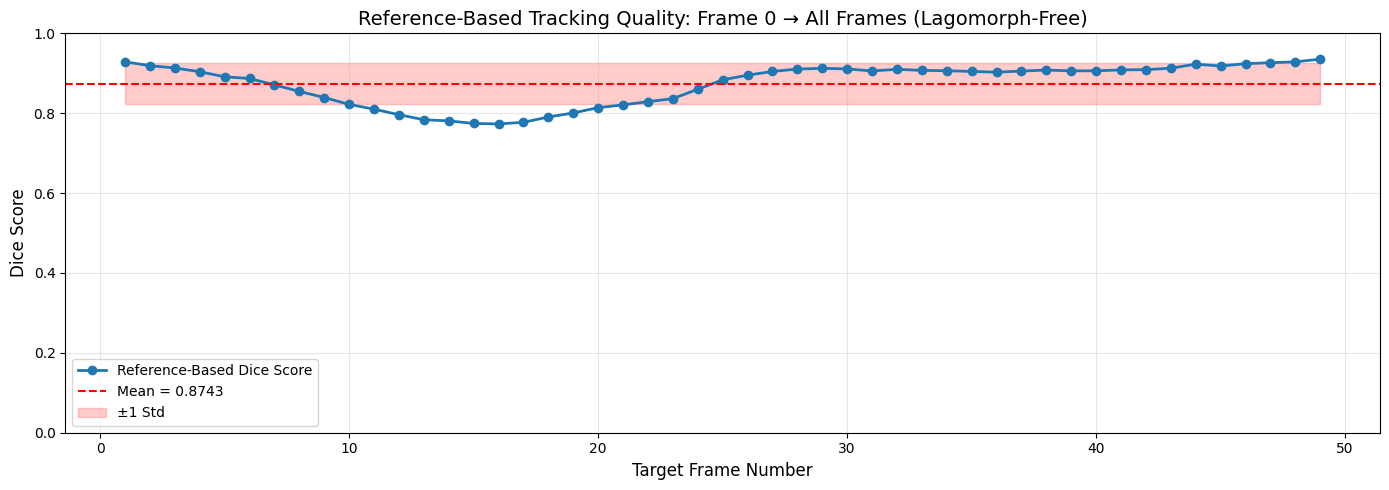

In [14]:
# Plot Dice scores over time
fig, ax = plt.subplots(1, 1, figsize=(14, 5))

frame_numbers = np.arange(1, len(dice_scores) + 1)
ax.plot(frame_numbers, dice_scores, 'o-', linewidth=2, markersize=6, label='Reference-Based Dice Score')
ax.axhline(y=dice_scores.mean(), color='r', linestyle='--', 
           label=f'Mean = {dice_scores.mean():.4f}')
ax.fill_between(frame_numbers, 
                dice_scores.mean() - dice_scores.std(),
                dice_scores.mean() + dice_scores.std(),
                alpha=0.2, color='r', label=f'±1 Std')

ax.set_xlabel('Target Frame Number', fontsize=12)
ax.set_ylabel('Dice Score', fontsize=12)
ax.set_title('Reference-Based Tracking Quality: Frame 0 → All Frames (Lagomorph-Free)', fontsize=14)
ax.grid(True, alpha=0.3)
ax.legend()
ax.set_ylim([0, 1])

plt.tight_layout()
plt.show()

## 10. Detailed Visualization: 8-Panel Comparison

Following the pattern from inference-LaMoD.ipynb

In [15]:
# Select frames to visualize
best_idx = dice_scores.argmax()
worst_idx = dice_scores.argmin()
mid_idx = len(dice_scores) // 2

check_indices = [0, 9, mid_idx, best_idx, worst_idx]
check_indices = sorted(list(set(check_indices)))

print(f"Visualizing frames: {[idx for idx in check_indices]}")
print(f"  Best Dice: Frame 0 -> {predictions[best_idx]['target_frame_idx']}, Dice = {dice_scores[best_idx]:.4f}")
print(f"  Worst Dice: Frame 0 -> {predictions[worst_idx]['target_frame_idx']}, Dice = {dice_scores[worst_idx]:.4f}")

Visualizing frames: [0, 9, np.int64(15), 24, np.int64(48)]
  Best Dice: Frame 0 -> 49, Dice = 0.9353
  Worst Dice: Frame 0 -> 16, Dice = 0.7732


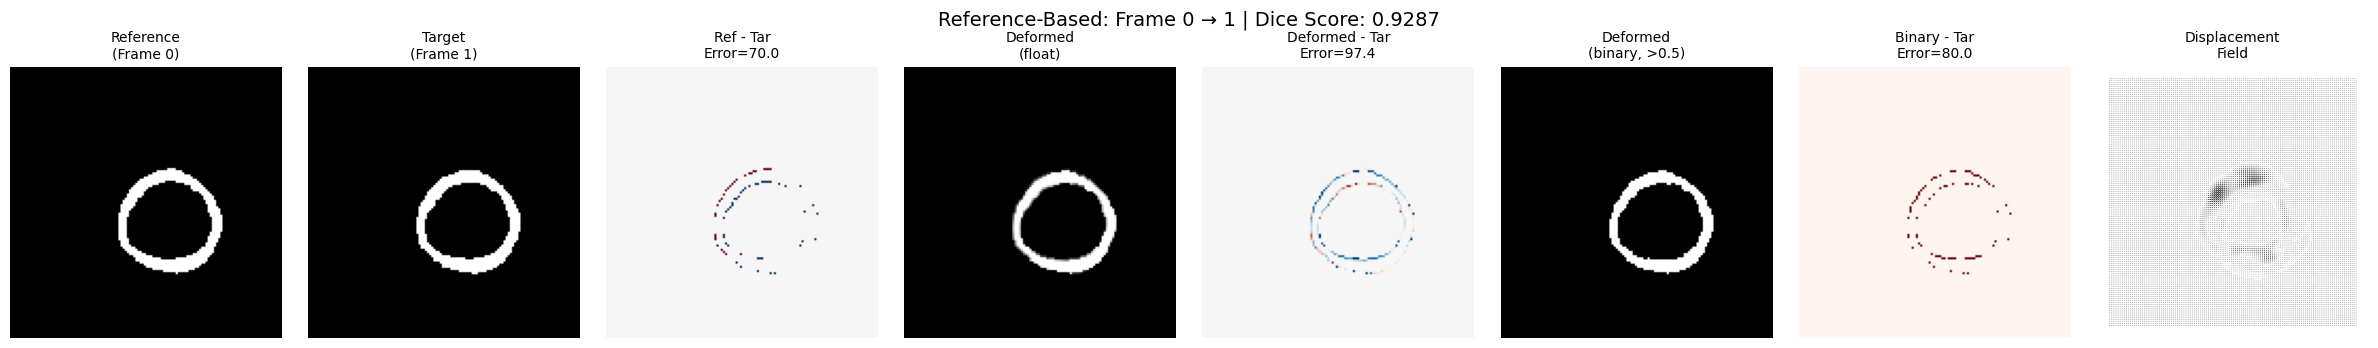

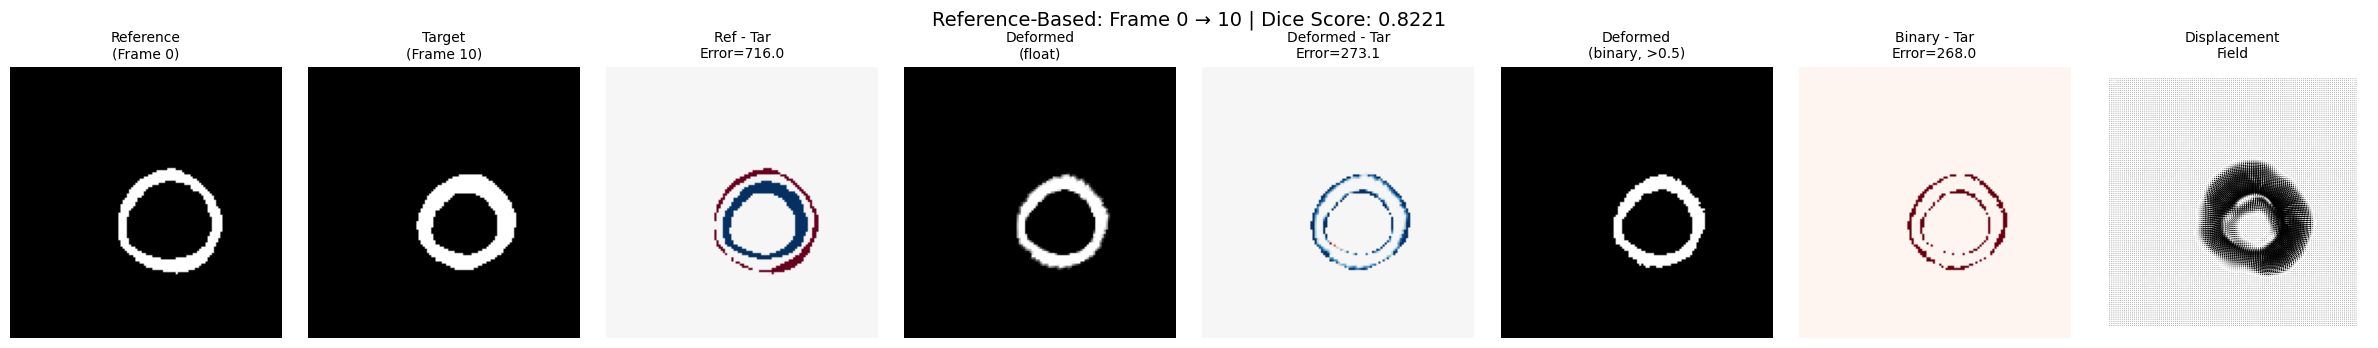

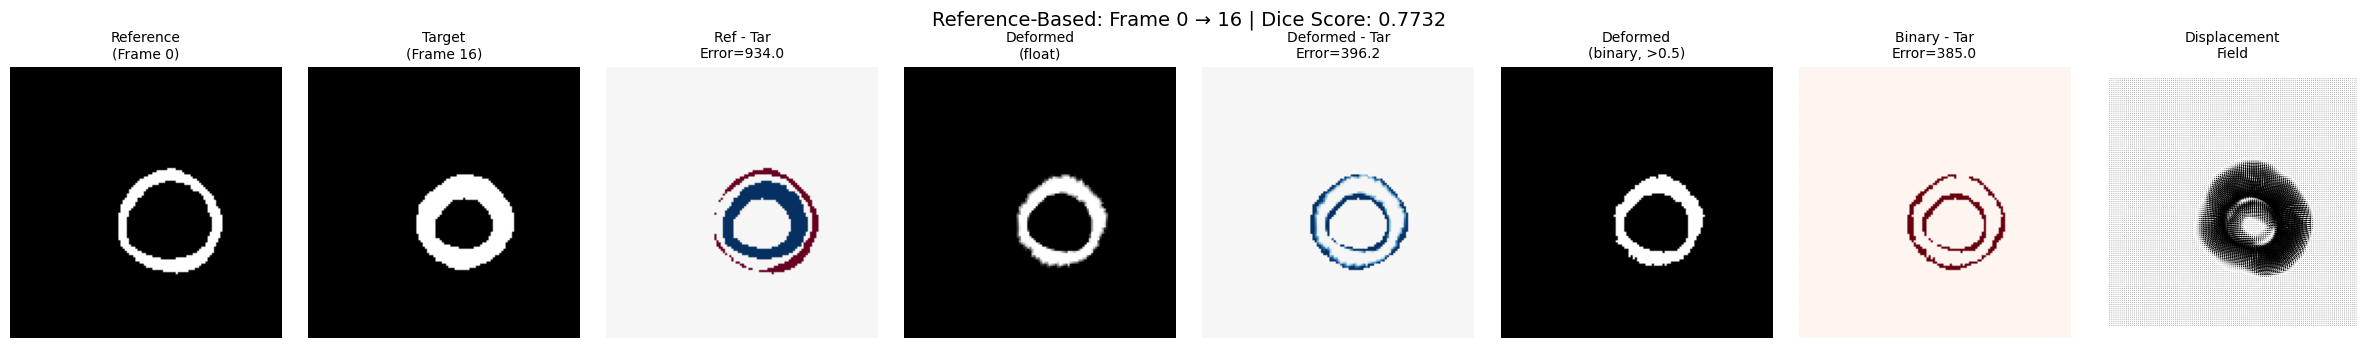

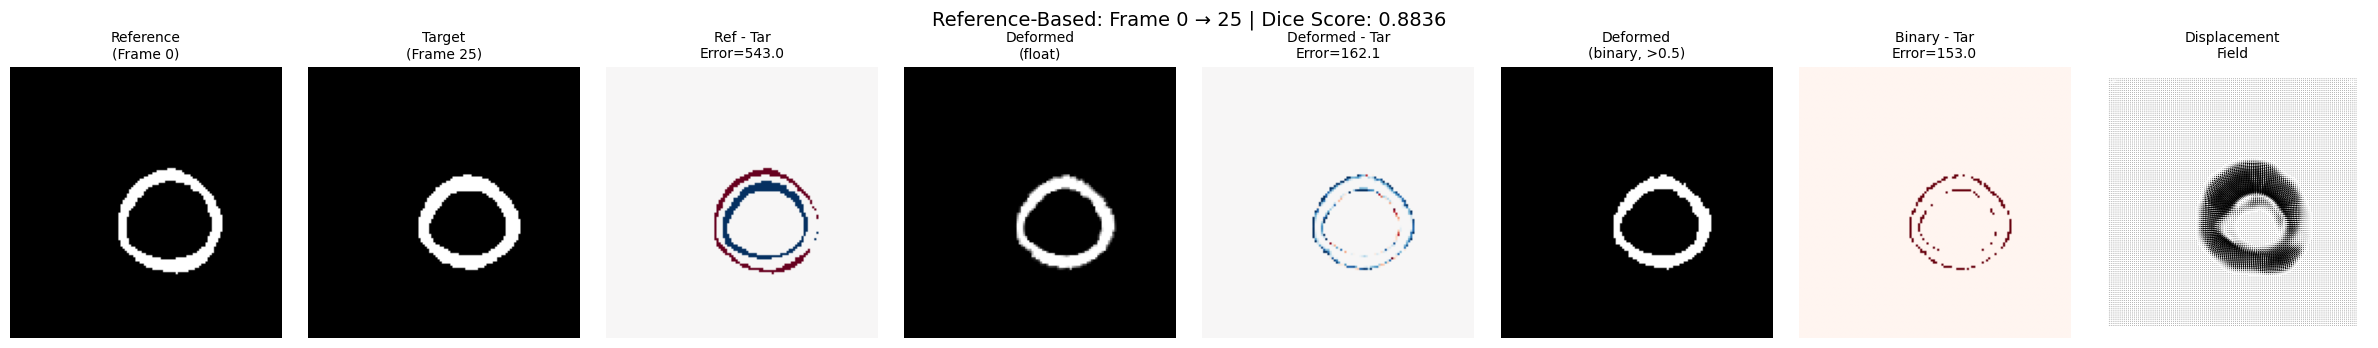

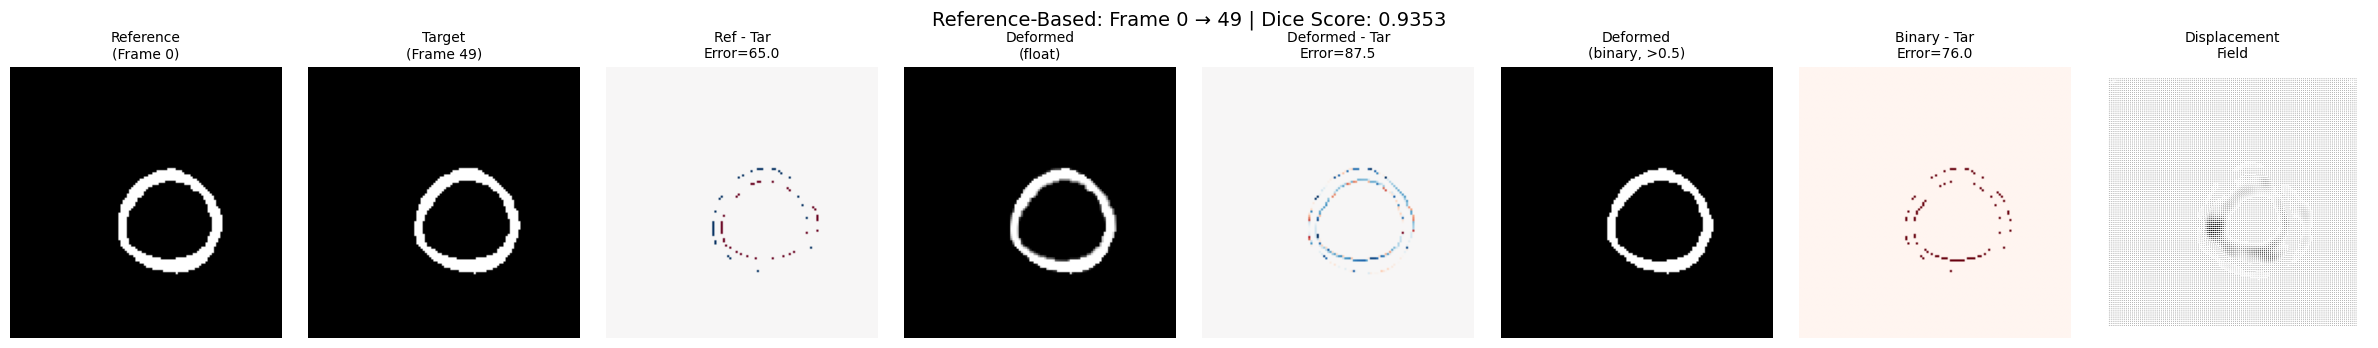

In [16]:
# Create 8-panel visualization (same pattern as inference-LaMoD.ipynb)
for check_idx in check_indices:
    pred = predictions[check_idx]
    target_idx = pred['target_frame_idx']
    
    src = pred['src'][0].astype(float)[0, 0]
    tar = pred['tar'][0].astype(float)[0, 0]
    src_tar_diff = src - tar
    
    deformed = pred['deformed_source_pred'][0][0][0]
    deformed_tar_diff = deformed - tar
    
    deformed_bin = deformed > 0.5
    deformed_bin_tar_diff = np.abs(deformed_bin - tar)
    
    disp_pred = pred['displacement_pred'][0, :, 0]  # (2, H, W)
    
    # Create figure
    fig, axs = plt.subplots(1, 8, figsize=(24, 3.5))
    
    # 1. Source (Reference)
    axs[0].imshow(src, cmap='gray', vmin=0, vmax=1)
    axs[0].set_title(f'Reference\n(Frame 0)', fontsize=10)
    axs[0].axis('off')
    
    # 2. Target
    axs[1].imshow(tar, cmap='gray', vmin=0, vmax=1)
    axs[1].set_title(f'Target\n(Frame {target_idx})', fontsize=10)
    axs[1].axis('off')
    
    # 3. Source - Target difference
    axs[2].imshow(src_tar_diff, cmap='RdBu_r', vmin=-1, vmax=1)
    axs[2].set_title(f'Ref - Tar\nError={np.abs(src_tar_diff).sum():.1f}', fontsize=10)
    axs[2].axis('off')
    
    # 4. Deformed (float)
    axs[3].imshow(deformed, cmap='gray', vmin=0, vmax=1)
    axs[3].set_title('Deformed\n(float)', fontsize=10)
    axs[3].axis('off')
    
    # 5. Deformed - Target difference
    axs[4].imshow(deformed_tar_diff, cmap='RdBu_r', vmin=-1, vmax=1)
    axs[4].set_title(f'Deformed - Tar\nError={np.abs(deformed_tar_diff).sum():.1f}', fontsize=10)
    axs[4].axis('off')
    
    # 6. Deformed (binary)
    axs[5].imshow(deformed_bin, cmap='gray', vmin=0, vmax=1)
    axs[5].set_title('Deformed\n(binary, >0.5)', fontsize=10)
    axs[5].axis('off')
    
    # 7. Deformed (binary) - Target difference
    axs[6].imshow(deformed_bin_tar_diff, cmap='Reds', vmin=0, vmax=1)
    axs[6].set_title(f'Binary - Tar\nError={np.abs(deformed_bin_tar_diff).sum():.1f}', fontsize=10)
    axs[6].axis('off')
    
    # 8. Displacement field (quiver)
    axs[7].quiver(disp_pred[0], disp_pred[1], scale=1, units='xy')
    axs[7].set_title('Displacement\nField', fontsize=10)
    axs[7].set_aspect('equal')
    axs[7].axis('off')
    
    # Invert y-axis for consistency
    for ax_idx in range(7):
        axs[ax_idx].invert_yaxis()
    
    # Add overall title with Dice score
    fig.suptitle(f'Reference-Based: Frame 0 → {target_idx} | Dice Score: {dice_scores[check_idx]:.4f}', 
                 fontsize=14, y=0.98)
    
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

## 11. Displacement Magnitude Analysis

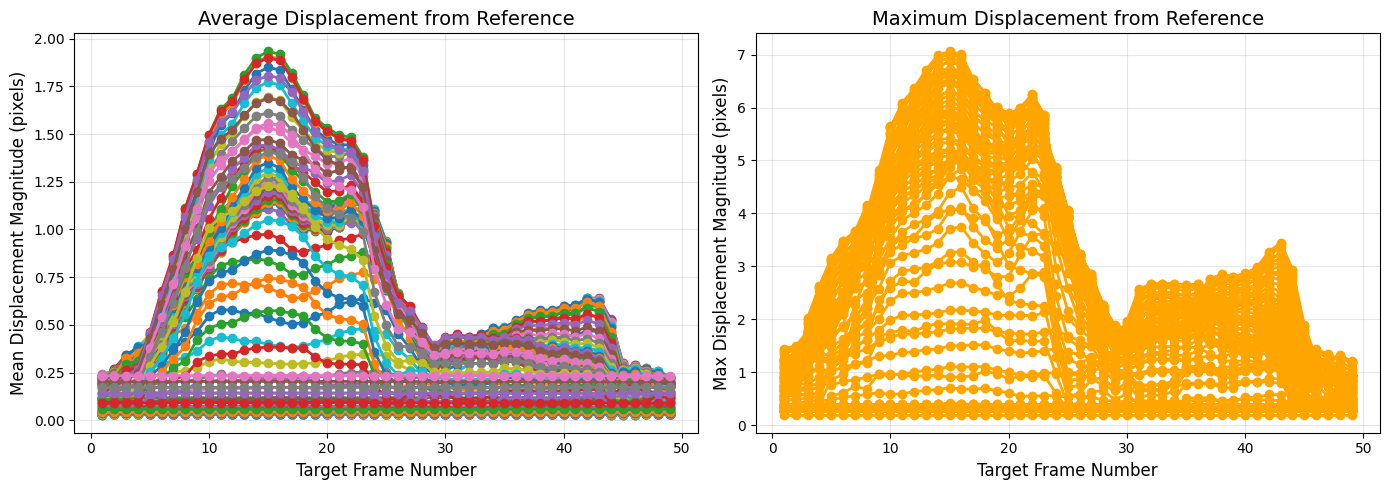

Peak mean displacement: 1.93 pixels at frame 1885
Peak max displacement: 7.06 pixels at frame 1885


In [17]:
# Extract all displacement fields
displacement_fields = []
for pred in predictions:
    disp = pred['displacement_pred'][0]  # (2, H, W)
    displacement_fields.append(disp)

displacement_fields = np.array(displacement_fields)  # (T-1, 2, H, W)

# Compute magnitudes
disp_magnitudes = np.sqrt(
    displacement_fields[:, 0, :, :]**2 + 
    displacement_fields[:, 1, :, :]**2
)

mean_disp_mag = disp_magnitudes.mean(axis=(1, 2))
max_disp_mag = disp_magnitudes.max(axis=(1, 2))

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

frame_numbers = np.arange(1, len(mean_disp_mag) + 1)

axes[0].plot(frame_numbers, mean_disp_mag, 'o-', linewidth=2, markersize=6)
axes[0].set_xlabel('Target Frame Number', fontsize=12)
axes[0].set_ylabel('Mean Displacement Magnitude (pixels)', fontsize=12)
axes[0].set_title('Average Displacement from Reference', fontsize=14)
axes[0].grid(True, alpha=0.3)

axes[1].plot(frame_numbers, max_disp_mag, 'o-', linewidth=2, markersize=6, color='orange')
axes[1].set_xlabel('Target Frame Number', fontsize=12)
axes[1].set_ylabel('Max Displacement Magnitude (pixels)', fontsize=12)
axes[1].set_title('Maximum Displacement from Reference', fontsize=14)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Peak mean displacement: {mean_disp_mag.max():.2f} pixels at frame {mean_disp_mag.argmax()+1}")
print(f"Peak max displacement: {max_disp_mag.max():.2f} pixels at frame {max_disp_mag.argmax()+1}")

## 12. Strain Analysis from Reference Displacement

In [18]:
displacement_fields.shape

(49, 2, 1, 128, 128)

In [19]:
from modules.data.processing.strain_analysis.pixelstrain import pixelstrain

H, W = 128, 128
X, Y = np.meshgrid(np.arange(W), np.arange(H))

# Rearrange displacement: (T-1, 2, H, W) -> (H, W, T-1) for X and Y
dXt = displacement_fields[:, 0, 0].transpose(1, 2, 0)
dYt = displacement_fields[:, 1, 0].transpose(1, 2, 0)

# Use reference frame mask
mask_ref = myocardium_mask[0].astype(bool)

print(f"Computing strain from reference-based displacement...")
Nfr = displacement_fields.shape[0]
strain = pixelstrain(
    X=X, Y=Y,
    dXt=dXt, dYt=dYt,
    mask=mask_ref,
    times=np.arange(Nfr)
)

print(f"Strain computed successfully!")
print(f"Available components: {list(strain.keys())}")

Computing strain from reference-based displacement...
Strain computed successfully!
Available components: ['vertices', 'faces', 'orientation', 'maskimage', 'XX', 'YY', 'XY', 'YX', 'RR', 'CC', 'RC', 'CR', 'p1', 'p2', 'p1or']


/tmp/ipykernel_3586511/3097707947.py:24: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


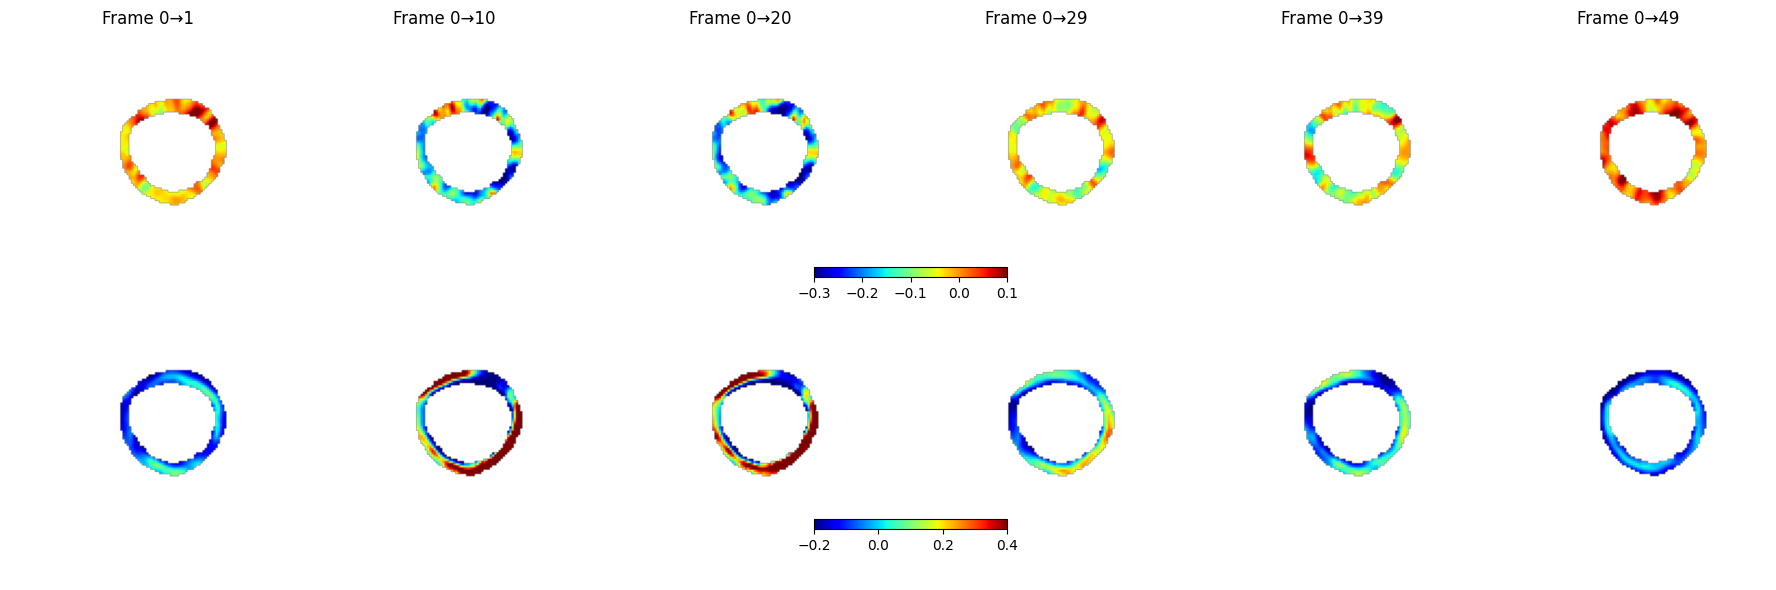

In [20]:
# Visualize strain maps
n_strain_frames = strain['CC'].shape[-1]
n_display = 6
frame_indices = np.linspace(0, n_strain_frames-1, n_display, dtype=int)

fig, axes = plt.subplots(2, n_display, figsize=(3*n_display, 6))

for i, frame_idx in enumerate(frame_indices):
    # Circumferential strain
    im1 = axes[0, i].imshow(strain['CC'][..., frame_idx], cmap='jet', vmin=-0.3, vmax=0.1)
    axes[0, i].set_title(f'Frame 0→{frame_idx+1}')
    axes[0, i].axis('off')
    
    # Radial strain
    im2 = axes[1, i].imshow(strain['RR'][..., frame_idx], cmap='jet', vmin=-0.2, vmax=0.4)
    axes[1, i].axis('off')

axes[0, 0].set_ylabel('Circumferential\nStrain', fontsize=12)
axes[1, 0].set_ylabel('Radial\nStrain', fontsize=12)

plt.colorbar(im1, ax=axes[0, :], orientation='horizontal', pad=0.05, fraction=0.046)
plt.colorbar(im2, ax=axes[1, :], orientation='horizontal', pad=0.05, fraction=0.046)

plt.tight_layout()
plt.show()

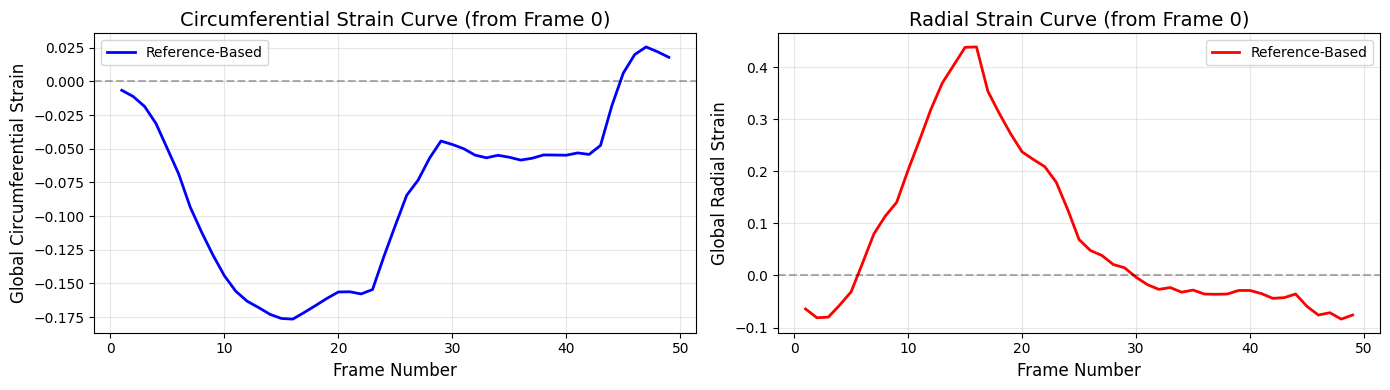

Peak Circumferential Strain: -0.1765 at frame 16
Peak Radial Strain: 0.4387 at frame 16


In [21]:
# Plot global strain curves
def compute_global_strain(strain_map, mask):
    """Compute mean strain over masked region for each time point"""
    n_frames = strain_map.shape[-1]
    global_strain = []
    
    for t in range(n_frames):
        frame_strain = strain_map[..., t]
        valid_strain = frame_strain[mask & ~np.isnan(frame_strain)]
        if len(valid_strain) > 0:
            global_strain.append(valid_strain.mean())
        else:
            global_strain.append(np.nan)
    
    return np.array(global_strain)

# Compute global strains
global_cc = compute_global_strain(strain['CC'], mask_ref)
global_rr = compute_global_strain(strain['RR'], mask_ref)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

frame_numbers = np.arange(1, len(global_cc) + 1)

axes[0].plot(frame_numbers, global_cc, 'b-', linewidth=2, label='Reference-Based')
axes[0].axhline(y=0, color='k', linestyle='--', alpha=0.3)
axes[0].set_xlabel('Frame Number', fontsize=12)
axes[0].set_ylabel('Global Circumferential Strain', fontsize=12)
axes[0].set_title('Circumferential Strain Curve (from Frame 0)', fontsize=14)
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(frame_numbers, global_rr, 'r-', linewidth=2, label='Reference-Based')
axes[1].axhline(y=0, color='k', linestyle='--', alpha=0.3)
axes[1].set_xlabel('Frame Number', fontsize=12)
axes[1].set_ylabel('Global Radial Strain', fontsize=12)
axes[1].set_title('Radial Strain Curve (from Frame 0)', fontsize=14)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Peak Circumferential Strain: {np.nanmin(global_cc):.4f} at frame {np.nanargmin(global_cc)+1}")
print(f"Peak Radial Strain: {np.nanmax(global_rr):.4f} at frame {np.nanargmax(global_rr)+1}")

## Summary

This notebook successfully demonstrated:

1. ✓ Loading UK Biobank cardiac cine MRI data
2. ✓ Automatic whole heart detection and preprocessing
3. ✓ Myocardium segmentation with CarSON
4. ✓ **Reference-based LaMoD tracking** from frame 0 to all other frames using **lagomorph-free implementation**
5. ✓ **Performance verification** via Dice scores
6. ✓ **Detailed 8-panel visualizations** (following inference-LaMoD.ipynb pattern)
7. ✓ Comprehensive strain analysis from reference frame

**Key Advantages:**
- Proper reference-based tracking (frame 0 = end-diastole)
- **Pure PyTorch implementation** - no lagomorph CUDA extensions required
- Uses official model loading infrastructure (`build_model`)
- Dice scores quantify tracking quality throughout cardiac cycle
- Clinically relevant strain measurements relative to baseline

**Lagomorph-Free Benefits:**
- ✓ No CUDA extension compilation needed
- ✓ Easier deployment and portability
- ✓ Compatible with any PyTorch environment
- ✓ Identical model architecture and weights
- ✓ Same computational accuracy